# Tarefa 2 — Regressão: probabilidade de sobrevivência com CART e MLP

Prevemos **`sobr`**, um valor real entre 0 e 1, usando exatamente os dez atributos
`idade`, `fc`, `fr`, `pas`, `spo2`, `temp`, `pr`, `sg`, `fx` e `queim`.
Comparamos **U** (subajuste), **E** (equilibrado) e **O** (sobreajuste) com os mesmos
cinco folds. Os nomes são hipóteses didáticas que verificamos nos erros reais.

Abra o notebook com a **pasta do projeto como diretório de trabalho** e selecione
o Python de **`.venv`**. Execute as células em ordem. Geramos um CSV próprio com
10.000 vítimas; os modelos ficam em `modelos/regressor/`. Os arquivos da Tarefa 1
permanecem intactos. Não há busca automática de hiperparâmetros.

O teste cego de 1.300 vítimas é `dados/teste/data.csv`, como na Tarefa 1. Sua estrutura foi
conferida; os valores só são carregados após a seleção e o retreino dos modelos.

## 1. Imports

Usamos regressão do scikit-learn. `threadpool_limits`, já utilizado na Tarefa 1,
limita o cálculo numérico a uma thread para evitar sobrecarga nas redes pequenas.
Os avisos de convergência permanecem visíveis.

In [1]:
from pathlib import Path
from importlib.metadata import version
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from IPython.display import display
from sklearn.model_selection import KFold
from sklearn.tree import DecisionTreeRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error
from threadpoolctl import threadpool_limits

from src import gerar_dados_vitimas as gerador

%matplotlib inline

## 2. Configurações gerais e reprodutibilidade

Mantemos a semente 42 e cinco folds da Tarefa 1. A quantidade é determinada
por `distrib_tri`: sua soma precisa ser exatamente 10.000.

In [2]:
RANDOM_STATE = 42
N_VITIMAS = 10_000
N_TESTE_CEGO = 1_300
N_FOLDS = 5
CASAS_DECIMAIS = 6

FEATURES = [
    "idade", "fc", "fr", "pas", "spo2", "temp", "pr", "sg", "fx", "queim"
]
TARGET = "sobr"
NOMES_TRI = {0: "verde", 1: "amarelo", 2: "vermelho", 3: "preto"}

BASE = Path.cwd()
CAMINHO_TREINO = BASE / "dados" / "treino" / "tarefa2_dados.csv"
CAMINHO_TESTE_CEGO = BASE / "dados" / "teste" / "data.csv"
PASTA_MODELOS = BASE / "modelos" / "regressor"
PASTA_GRAFICOS = BASE / "graficos" / "regressor"

config_geracao = {
    "distrib_tri": {0: 2_500, 1: 2_500, 2: 2_500, 3: 2_500},
    "media_idade": 35,
    "desvio_idade": 15,
    "nivel_ruido": 0.02,
    "seed": RANDOM_STATE,
}

assert sum(config_geracao["distrib_tri"].values()) == N_VITIMAS
assert len(FEATURES) == 10 and len(set(FEATURES)) == 10
assert CAMINHO_TREINO.resolve() != CAMINHO_TESTE_CEGO.resolve()
pd.set_option("display.max_columns", 20)
pd.set_option("display.float_format", f"{{:.{CASAS_DECIMAIS}f}}".format)
display(pd.Series(config_geracao, name="Parâmetros de geração").to_frame())
display(pd.Series({
    "Python": sys.version.split()[0],
    **{pacote: version(pacote) for pacote in (
        "numpy", "pandas", "scikit-learn", "matplotlib", "joblib"
    )},
}, name="Versão").to_frame())

,Parâmetros de geração
distrib_tri,"{0: 2500, 1: 2500, 2: 2500, 3: 2500}"
media_idade,35
desvio_idade,15
nivel_ruido,0.020000
seed,42


,Versão
Python,3.12.14
numpy,2.5.3
pandas,3.0.6
scikit-learn,1.9.1
matplotlib,3.11.2
joblib,1.6.0


## 3. Geração e carregamento das 10.000 vítimas

O gerador não possui argumentos de linha de comando. Sua API real é
`gerar_dataset_vitimas(distrib_tri, media_idade, desvio_idade, nivel_ruido, seed)`;
ela **retorna um DataFrame e grava um CSV** em `OUTPUT_CSV`. Os padrões da função
são os mesmos parâmetros acima. Executar diretamente o script chama outro
experimento, com 1.300 vítimas e `seed=None`; por isso importamos o módulo.

Geramos dados específicos da Tarefa 2 para conhecer com certeza a procedência.
Redirecionamos `OUTPUT_CSV` em memória e o restauramos em seguida, sem editar
`src/gerar_dados_vitimas.py`. A geração é determinística e se repete a cada execução.
O histograma abaixo é produzido pelo próprio gerador.

**Particularidades do código existente:** as idades vêm de uma normal, são
limitadas a [1, 90] e convertidas para inteiros. `desvio_idade` é o parâmetro da
normal, não o DPA observado. `nivel_ruido=0.02` afeta os sinais e as variáveis de
triagem; em `calcular_sobr_fisiologica`, o ruído efetivo é uma normal com desvio
**0,04**, fixado no código, e a saída é arredondada a duas casas. Há duas amostragens
desse ruído, sendo a primeira sobrescrita. Preservamos esse comportamento.
`tri` usa 0=verde, 1=amarelo, 2=vermelho e 3=preto; o ruído pode alterar as contagens.


Dataset salvo com sucesso em: /home/gusfipe/Projects/sist-inteligentes/tarefa2_dados.csv

Distribuição final de vítimas por classificação START (após ruído):
  0 (Verde): 2478 (24.8%)
  1 (Amarelo): 2516 (25.2%)
  2 (Vermelho): 2534 (25.3%)
  3 (Preto): 2472 (24.7%)
total de vítimas: 10000


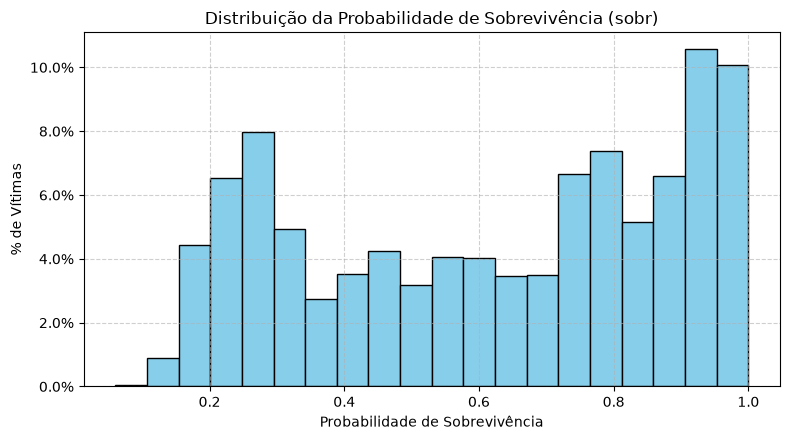

CSV de treino da Tarefa 2: tarefa2_dados.csv


In [3]:
saida_original_gerador = gerador.OUTPUT_CSV
try:
    gerador.OUTPUT_CSV = CAMINHO_TREINO
    df_gerado = gerador.gerar_dataset_vitimas(**config_geracao)
finally:
    gerador.OUTPUT_CSV = saida_original_gerador

df = pd.read_csv(CAMINHO_TREINO)
pd.testing.assert_frame_equal(df, df_gerado)
assert len(df) == N_VITIMAS
print("CSV de treino da Tarefa 2:", CAMINHO_TREINO.name)

## 4. Inspeção básica

Conferimos estrutura, tipos, valores ausentes e o intervalo do alvo. Usamos
`tri` apenas para descrever a distribuição do dataset no relatório.

In [4]:
print("Dimensões:", df.shape)
display(df.head())
print("Colunas:", df.columns.tolist())
assert set(FEATURES + [TARGET, "tri"]).issubset(df.columns)
assert len(df) == N_VITIMAS
assert df.isna().sum().sum() == 0, "Há valores ausentes no dataset."
assert all(pd.api.types.is_numeric_dtype(df[coluna]) for coluna in FEATURES + [TARGET])
assert np.isfinite(df[FEATURES + [TARGET]].to_numpy(dtype=float)).all()
assert df[TARGET].between(0, 1).all(), "sobr deve estar em [0, 1]."
assert df["tri"].isin(NOMES_TRI).all()

display(pd.DataFrame({"Tipo": df.dtypes, "Ausentes": df.isna().sum()}))
display(df[TARGET].describe().loc[["count", "mean", "std", "min", "max"]].to_frame())
contagem_tri = df["tri"].value_counts().reindex(list(NOMES_TRI), fill_value=0)
media_idade_observada = df["idade"].mean()
dpa_idade_observado = df["idade"].std(ddof=1)
display(pd.DataFrame({
    "Triagem": list(NOMES_TRI.values()), "Vítimas": contagem_tri.to_numpy()
}, index=pd.Index(NOMES_TRI, name="tri")))

Dimensões: (10000, 14)


,idade,fc,fr,pas,spo2,temp,pr,sg,fx,queim,gcs,avpu,tri,sobr
0,42,105,21,90,94,35.500000,1,2,0,0,12,1,1,0.770000
1,32,122,12,66,86,32.400000,0,1,0,3,7,3,2,0.380000
2,44,122,8,162,86,38.500000,1,1,0,2,11,2,2,0.720000
3,57,68,13,121,99,36.800000,1,0,0,0,14,1,0,0.950000
4,31,85,25,89,92,38.200000,1,2,1,1,11,2,1,0.670000


Colunas: ['idade', 'fc', 'fr', 'pas', 'spo2', 'temp', 'pr', 'sg', 'fx', 'queim', 'gcs', 'avpu', 'tri', 'sobr']


,Tipo,Ausentes
idade,int64,0
fc,int64,0
fr,int64,0
pas,int64,0
spo2,int64,0
temp,float64,0
pr,int64,0
sg,int64,0
fx,int64,0
queim,int64,0


,sobr
count,10000.000000
mean,0.620676
std,0.271852
min,0.060000
max,1.000000


,Triagem,Vítimas
tri,,
0,verde,2478
1,amarelo,2516
2,vermelho,2534
3,preto,2472


## 5. Preparação explícita de X e y

**X** contém as dez características originais; **y** contém a probabilidade
`sobr`. Não criamos atributos derivados. `gcs`, `avpu` e `tri` ficam fora de X.

In [5]:
X = df[FEATURES].copy()
y = df[TARGET].copy()

assert X.shape == (N_VITIMAS, 10)
assert len(X) == len(y) == N_VITIMAS
assert X.columns.tolist() == FEATURES
assert set(X.columns) == set(FEATURES)
assert "gcs" not in X.columns
assert "avpu" not in X.columns
assert "tri" not in X.columns
assert "sobr" not in X.columns
assert y.name == "sobr"
print("Entradas:", X.columns.tolist())
print("Alvo:", y.name)

Entradas: ['idade', 'fc', 'fr', 'pas', 'spo2', 'temp', 'pr', 'sg', 'fx', 'queim']
Alvo: sobr


## 6. Validação cruzada e métricas

Usamos **KFold**, com embaralhamento e semente fixa. Materializamos os índices
para que todos os modelos sejam avaliados nas mesmas divisões. Em cada fold,
8.000 vítimas treinam o modelo e 2.000 o validam, sem contato com o teste cego.

Adotamos a convenção matemática: **MSE = média dos erros ao quadrado**;
**RMSE = √MSE**. A validação usa MSE. Calculamos a diferença **absoluta em cada
fold**, depois sua média. Todo DPA usa **`ddof=1`**. As funções abaixo apenas
resumem números e formatam tabelas; o treinamento permanece explícito.

In [6]:
kfold = KFold(n_splits=N_FOLDS, shuffle=True, random_state=RANDOM_STATE)
folds = list(kfold.split(X))
assert len(folds) == N_FOLDS
assert np.array_equal(np.sort(np.concatenate([val for _, val in folds])), np.arange(len(X)))
for treino, validacao in folds:
    assert len(np.intersect1d(treino, validacao)) == 0
    assert len(treino) + len(validacao) == len(X)
print(f"KFold: {N_FOLDS} folds; random_state={RANDOM_STATE}")


def resumir_cv(train_mse_folds, val_mse_folds):
    treino = np.asarray(train_mse_folds, dtype=float)
    validacao = np.asarray(val_mse_folds, dtype=float)
    diferencas = np.abs(validacao - treino)
    assert len(treino) == len(validacao) == N_FOLDS
    assert np.isfinite(treino).all() and np.isfinite(validacao).all()
    return {
        "train_mean": treino.mean(), "train_std": treino.std(ddof=1),
        "val_mean": validacao.mean(), "val_std": validacao.std(ddof=1),
        "diff_mean": diferencas.mean(), "diff_std": diferencas.std(ddof=1),
    }


def tabela_media_dpa(resumos):
    tabela = pd.DataFrame(index=[
        "TREINO MSE (dpa)", "VALIDAÇÃO MSE (dpa)", "MÉDIA DAS DIFS. (dpa)"
    ])
    for nome, resumo in resumos.items():
        tabela[nome] = [
            f"{resumo[media]:.{CASAS_DECIMAIS}f} ({resumo[dpa]:.{CASAS_DECIMAIS}f})"
            for media, dpa in [
                ("train_mean", "train_std"), ("val_mean", "val_std"), ("diff_mean", "diff_std")
            ]
        ]
    return tabela

KFold: 5 folds; random_state=42


## 7. CART — hiperparâmetros definitivos U/E/O

**U:** profundidade 2 e ao menos 100 vítimas por folha limitam a capacidade.
**E:** profundidade 10 e ao menos 20 vítimas por folha permitem aprender relações
sem individualizar cada vítima. **O:** árvore sem limite de profundidade e folhas
com uma amostra podem memorizar o ruído.

Em um ajuste manual, a alternativa equilibrada com profundidade 8 e mínimo de
10 amostras por folha teve MSE médio de validação 0,002376; profundidade 10 com
20 por folha teve 0,002332 nos mesmos cinco folds. Mantivemos a segunda, com
menor erro e DPA de validação, verificando seu gap na tabela abaixo. Nenhum
valor do teste cego participou dessa decisão.

In [7]:
cart_configs = {
    "U": {"max_depth": 2, "min_samples_leaf": 100},
    "E": {"max_depth": 10, "min_samples_leaf": 20},
    "O": {"max_depth": None, "min_samples_leaf": 1},
}
# Uma Series de objetos por coluna preserva None e os inteiros.
tabela_hiperparametros_cart = pd.DataFrame({
    nome: pd.Series(parametros, dtype=object)
    for nome, parametros in cart_configs.items()
})
tabela_hiperparametros_cart.loc["criterion"] = "squared_error"
tabela_hiperparametros_cart.loc["random_state"] = RANDOM_STATE
display(tabela_hiperparametros_cart)

,U,E,O
max_depth,2,10,None
min_samples_leaf,100,20,1
criterion,squared_error,squared_error,squared_error
random_state,42,42,42


### 7.1. Treinamento e resultados individuais dos folds do CART

Cada iteração cria uma árvore nova. O CART recebe as características originais,
sem padronização. Guardamos separadamente os erros de treino, validação e o gap.

In [8]:
resultados_cart = {}
registros_cart = []

for configuracao, parametros in cart_configs.items():
    train_mse_folds = []
    val_mse_folds = []
    diff_folds = []

    for numero_fold, (indices_treino, indices_validacao) in enumerate(folds, start=1):
        X_train = X.iloc[indices_treino]
        X_val = X.iloc[indices_validacao]
        y_train = y.iloc[indices_treino]
        y_val = y.iloc[indices_validacao]

        cart = DecisionTreeRegressor(**parametros, random_state=RANDOM_STATE)
        cart.fit(X_train, y_train)
        y_train_pred = cart.predict(X_train)
        y_val_pred = cart.predict(X_val)

        mse_treino = mean_squared_error(y_train, y_train_pred)
        mse_validacao = mean_squared_error(y_val, y_val_pred)
        diferenca = abs(mse_validacao - mse_treino)
        train_mse_folds.append(mse_treino)
        val_mse_folds.append(mse_validacao)
        diff_folds.append(diferenca)
        registros_cart.append({
            "modelo": f"CART {configuracao}", "fold": numero_fold,
            "mse_treino": mse_treino, "mse_validacao": mse_validacao,
            "diferenca": diferenca,
        })

    resultados_cart[configuracao] = {
        "train_mse_folds": train_mse_folds,
        "val_mse_folds": val_mse_folds,
        "diff_folds": diff_folds,
        "resumo": resumir_cv(train_mse_folds, val_mse_folds),
    }

tabela_folds_cart = pd.DataFrame(registros_cart)
display(tabela_folds_cart)

,modelo,fold,mse_treino,mse_validacao,diferenca
0,CART U,1,0.006538,0.007244,0.000707
1,CART U,2,0.006654,0.006795,0.000142
2,CART U,3,0.006753,0.006380,0.000373
3,CART U,4,0.006668,0.006741,0.000073
4,CART U,5,0.006759,0.006372,0.000387
5,CART E,1,0.001799,0.002336,0.000537
6,CART E,2,0.001783,0.002386,0.000602
7,CART E,3,0.001795,0.002264,0.000469
8,CART E,4,0.001783,0.002300,0.000518
9,CART E,5,0.001788,0.002376,0.000587


### 7.2. Comparação e leitura de U/E/O do CART

U apresenta erros relativamente altos nos dois conjuntos. O quase zera o erro
de treino, mas tem erro de validação e gap maiores. E deve combinar erro de
validação baixo com gap moderado e estabilidade. A tabela numérica conserva a
precisão dos cálculos; **média (DPA)** é apenas o formato do relatório.

In [9]:
resumo_cart = pd.DataFrame({
    configuracao: resultado["resumo"]
    for configuracao, resultado in resultados_cart.items()
}).T
tabela_cart = tabela_media_dpa({
    f"CART {configuracao}": resultado["resumo"]
    for configuracao, resultado in resultados_cart.items()
})
display(resumo_cart)
display(tabela_cart)
for configuracao, resumo in resumo_cart.iterrows():
    print(f"CART {configuracao}: treino={resumo.train_mean:.6f}; "
          f"validação={resumo.val_mean:.6f}; gap={resumo.diff_mean:.6f}")

,train_mean,train_std,val_mean,val_std,diff_mean,diff_std
U,0.006674,0.000090,0.006706,0.000359,0.000336,0.000249
E,0.001790,0.000007,0.002332,0.000051,0.000543,0.000054
O,0.000000,0.000000,0.003710,0.000069,0.003710,0.000069


,CART U,CART E,CART O
TREINO MSE (dpa),0.006674 (0.000090),0.001790 (0.000007),0.000000 (0.000000)
VALIDAÇÃO MSE (dpa),0.006706 (0.000359),0.002332 (0.000051),0.003710 (0.000069)
MÉDIA DAS DIFS. (dpa),0.000336 (0.000249),0.000543 (0.000054),0.003710 (0.000069)


CART U: treino=0.006674; validação=0.006706; gap=0.000336
CART E: treino=0.001790; validação=0.002332; gap=0.000543
CART O: treino=0.000000; validação=0.003710; gap=0.003710


### 7.3. Escolha do melhor CART

Priorizamos o **MSE médio de validação**; o menor gap e o menor DPA de validação
desempatam. A tabela mantém todos os critérios visíveis para revisão, sem usar
o erro de treino como critério de vitória nem forçar a escolha de E.

In [10]:
ordenacao_cart = resumo_cart.sort_values(["val_mean", "diff_mean", "val_std"])
display(ordenacao_cart[["val_mean", "diff_mean", "val_std"]])
melhor_cart_config = ordenacao_cart.index[0]
parametros_melhor_cart = cart_configs[melhor_cart_config].copy()
print("Melhor CART:", melhor_cart_config)
print("Hiperparâmetros:", parametros_melhor_cart)
print("Critério: menor MSE médio de validação; gap e DPA conferidos acima.")

,val_mean,diff_mean,val_std
E,0.002332,0.000543,0.000051
O,0.003710,0.003710,0.000069
U,0.006706,0.000336,0.000359


Melhor CART: E
Hiperparâmetros: {'max_depth': 10, 'min_samples_leaf': 20}
Critério: menor MSE médio de validação; gap e DPA conferidos acima.


## 8. Rede neural MLP — hiperparâmetros definitivos U/E/O

**U:** dois neurônios e ativação `tanh` limitam a representação; `alpha=1` adiciona
regularização. O subajuste não é produzido interrompendo o treinamento.
**E:** duas camadas (32, 16), `relu` e regularização 0,1.
**O:** três camadas (64, 64, 32), `relu` e regularização mínima, com tempo suficiente
para aprender inclusive parte do ruído. A topologia permanece moderada.

Uma verificação manual de U com `alpha=1` e `alpha=10` no primeiro fold indicou
mais subajuste com regularização maior. Mantivemos `alpha=1`, pois a capacidade
de apenas dois neurônios já permite observar subajuste sem penalização excessiva.
As três configurações finais são avaliadas em **todos** os folds abaixo.

Todas usam Adam e `early_stopping=False`, aproveitando todas as vítimas de treino
de cada fold. `max_iter` é um teto; `tol` e `n_iter_no_change` permitem encerrar
quando a perda deixa de melhorar. Registramos as iterações para acompanhar isso.

In [11]:
rn_configs = {
    "U": {
        "hidden_layer_sizes": (2,), "activation": "tanh", "solver": "adam",
        "alpha": 1.0, "learning_rate_init": 0.001,
        "max_iter": 1500, "tol": 1e-6, "n_iter_no_change": 40,
    },
    "E": {
        "hidden_layer_sizes": (32, 16), "activation": "relu", "solver": "adam",
        "alpha": 0.1, "learning_rate_init": 0.001,
        "max_iter": 1500, "tol": 1e-6, "n_iter_no_change": 40,
    },
    "O": {
        "hidden_layer_sizes": (64, 64, 32), "activation": "relu", "solver": "adam",
        "alpha": 1e-6, "learning_rate_init": 0.001,
        "max_iter": 2000, "tol": 1e-7, "n_iter_no_change": 60,
    },
}
tabela_hiperparametros_rn = pd.DataFrame(rn_configs, dtype=object).rename(index={
    "hidden_layer_sizes": "Topologia", "activation": "Função de ativação",
    "learning_rate_init": "Learning rate", "solver": "Solver",
})
tabela_hiperparametros_rn.loc["early_stopping"] = False
tabela_hiperparametros_rn.loc["random_state"] = RANDOM_STATE
# Parâmetros pequenos usam notação científica para não parecerem zero.
for parametro in ["alpha", "tol"]:
    tabela_hiperparametros_rn.loc[parametro] = [
        f"{rn_configs[nome][parametro]:g}" for nome in rn_configs
    ]
display(tabela_hiperparametros_rn)

,U,E,O
Topologia,"(2,)","(32, 16)","(64, 64, 32)"
Função de ativação,tanh,relu,relu
Solver,adam,adam,adam
alpha,1,0.1,1e-06
Learning rate,0.001000,0.001000,0.001000
max_iter,1500,1500,2000
tol,1e-06,1e-06,1e-07
n_iter_no_change,40,40,60
early_stopping,False,False,False
random_state,42,42,42


### 8.1. Padronização e treinamento por fold

A MLP precisa de padronização porque os atributos possuem escalas diferentes.
Criamos **um StandardScaler novo por fold**, ajustado **somente em X_train**.
X_val é apenas transformado por ele. Uma MLP nova aprende somente com o treino.
Não usamos informações do fold de validação para aprender a escala.

In [12]:
resultados_rn = {}
registros_rn = []

for configuracao, parametros in rn_configs.items():
    train_mse_folds = []
    val_mse_folds = []
    diff_folds = []
    iteracoes_folds = []

    for numero_fold, (indices_treino, indices_validacao) in enumerate(folds, start=1):
        X_train = X.iloc[indices_treino]
        X_val = X.iloc[indices_validacao]
        y_train = y.iloc[indices_treino]
        y_val = y.iloc[indices_validacao]

        # O scaler aprende apenas com o treino do fold para evitar vazamento.
        scaler = StandardScaler()
        X_train_scaled = scaler.fit_transform(X_train)
        X_val_scaled = scaler.transform(X_val)
        assert np.all(np.asarray(scaler.n_samples_seen_) == len(indices_treino))

        rn = MLPRegressor(**parametros, early_stopping=False, random_state=RANDOM_STATE)
        with threadpool_limits(limits=1):
            rn.fit(X_train_scaled, y_train)
            y_train_pred = rn.predict(X_train_scaled)
            y_val_pred = rn.predict(X_val_scaled)

        mse_treino = mean_squared_error(y_train, y_train_pred)
        mse_validacao = mean_squared_error(y_val, y_val_pred)
        diferenca = abs(mse_validacao - mse_treino)
        train_mse_folds.append(mse_treino)
        val_mse_folds.append(mse_validacao)
        diff_folds.append(diferenca)
        iteracoes_folds.append(rn.n_iter_)
        registros_rn.append({
            "modelo": f"RN {configuracao}", "fold": numero_fold,
            "mse_treino": mse_treino, "mse_validacao": mse_validacao,
            "diferenca": diferenca, "iteracoes": rn.n_iter_,
        })
        print(f"RN {configuracao}, fold {numero_fold}: "
              f"treino={mse_treino:.6f}, validação={mse_validacao:.6f}, "
              f"gap={diferenca:.6f}, iterações={rn.n_iter_}")

    resultados_rn[configuracao] = {
        "train_mse_folds": train_mse_folds,
        "val_mse_folds": val_mse_folds,
        "diff_folds": diff_folds,
        "iteracoes_folds": iteracoes_folds,
        "resumo": resumir_cv(train_mse_folds, val_mse_folds),
    }

tabela_folds_rn = pd.DataFrame(registros_rn)
display(tabela_folds_rn)

RN U, fold 1: treino=0.002699, validação=0.002706, gap=0.000007, iterações=393
RN U, fold 2: treino=0.002702, validação=0.002678, gap=0.000024, iterações=371
RN U, fold 3: treino=0.002734, validação=0.002658, gap=0.000076, iterações=397
RN U, fold 4: treino=0.002673, validação=0.002689, gap=0.000016, iterações=395
RN U, fold 5: treino=0.002682, validação=0.002815, gap=0.000133, iterações=377
RN E, fold 1: treino=0.001748, validação=0.001786, gap=0.000038, iterações=392
RN E, fold 2: treino=0.001748, validação=0.001731, gap=0.000017, iterações=404
RN E, fold 3: treino=0.001755, validação=0.001755, gap=0.000000, iterações=395
RN E, fold 4: treino=0.001753, validação=0.001762, gap=0.000009, iterações=371
RN E, fold 5: treino=0.001732, validação=0.001832, gap=0.000100, iterações=372
RN O, fold 1: treino=0.000612, validação=0.002997, gap=0.002385, iterações=1039
RN O, fold 2: treino=0.000631, validação=0.002834, gap=0.002202, iterações=874
RN O, fold 3: treino=0.000599, validação=0.003037, 

,modelo,fold,mse_treino,mse_validacao,diferenca,iteracoes
0,RN U,1,0.002699,0.002706,0.000007,393
1,RN U,2,0.002702,0.002678,0.000024,371
2,RN U,3,0.002734,0.002658,0.000076,397
3,RN U,4,0.002673,0.002689,0.000016,395
4,RN U,5,0.002682,0.002815,0.000133,377
5,RN E,1,0.001748,0.001786,0.000038,392
6,RN E,2,0.001748,0.001731,0.000017,404
7,RN E,3,0.001755,0.001755,0.000000,395
8,RN E,4,0.001753,0.001762,0.000009,371
9,RN E,5,0.001732,0.001832,0.000100,372


### 8.2. Comparação e leitura de U/E/O da MLP

U tem capacidade pequena e erros maiores nos dois conjuntos. O reduz bastante
o erro de treino, mas aumenta o gap e o erro de validação. E generaliza melhor,
com erros próximos. Conferimos as médias, os DPAs e as iterações realmente
obtidas; uma rede maior não é garantia de pior generalização em qualquer dataset.

In [13]:
resumo_rn = pd.DataFrame({
    configuracao: resultado["resumo"]
    for configuracao, resultado in resultados_rn.items()
}).T
tabela_rn = tabela_media_dpa({
    f"RN {configuracao}": resultado["resumo"]
    for configuracao, resultado in resultados_rn.items()
})
display(resumo_rn)
display(tabela_rn)
display(pd.DataFrame({
    configuracao: resultado["iteracoes_folds"]
    for configuracao, resultado in resultados_rn.items()
}, index=pd.Index(range(1, N_FOLDS + 1), name="Fold")))
for configuracao, resumo in resumo_rn.iterrows():
    print(f"RN {configuracao}: treino={resumo.train_mean:.6f}; "
          f"validação={resumo.val_mean:.6f}; gap={resumo.diff_mean:.6f}")

,train_mean,train_std,val_mean,val_std,diff_mean,diff_std
U,0.002698,0.000023,0.002709,0.000062,0.000051,0.000053
E,0.001747,0.000009,0.001773,0.000038,0.000033,0.000040
O,0.000629,0.000026,0.002959,0.000077,0.002330,0.000090


,RN U,RN E,RN O
TREINO MSE (dpa),0.002698 (0.000023),0.001747 (0.000009),0.000629 (0.000026)
VALIDAÇÃO MSE (dpa),0.002709 (0.000062),0.001773 (0.000038),0.002959 (0.000077)
MÉDIA DAS DIFS. (dpa),0.000051 (0.000053),0.000033 (0.000040),0.002330 (0.000090)


,U,E,O
Fold,,,
1,393,392,1039
2,371,404,874
3,397,395,1277
4,395,371,1184
5,377,372,976


RN U: treino=0.002698; validação=0.002709; gap=0.000051
RN E: treino=0.001747; validação=0.001773; gap=0.000033
RN O: treino=0.000629; validação=0.002959; gap=0.002330


### 8.3. Escolha da melhor MLP

Aplicamos os mesmos critérios do CART: menor MSE médio de validação, com gap
e DPA visíveis. Nenhum resultado do teste cego entra nessa escolha.

In [14]:
ordenacao_rn = resumo_rn.sort_values(["val_mean", "diff_mean", "val_std"])
display(ordenacao_rn[["val_mean", "diff_mean", "val_std"]])
melhor_rn_config = ordenacao_rn.index[0]
parametros_melhor_rn = rn_configs[melhor_rn_config].copy()
print("Melhor RN:", melhor_rn_config)
print("Hiperparâmetros:", parametros_melhor_rn)
print("Critério: menor MSE médio de validação; gap e DPA conferidos acima.")

,val_mean,diff_mean,val_std
E,0.001773,0.000033,0.000038
U,0.002709,0.000051,0.000062
O,0.002959,0.002330,0.000077


Melhor RN: E
Hiperparâmetros: {'hidden_layer_sizes': (32, 16), 'activation': 'relu', 'solver': 'adam', 'alpha': 0.1, 'learning_rate_init': 0.001, 'max_iter': 1500, 'tol': 1e-06, 'n_iter_no_change': 40}
Critério: menor MSE médio de validação; gap e DPA conferidos acima.


## 9. Melhor CART × melhor MLP — antes do teste cego

Copiamos os resultados dos mesmos folds, sem recalcular modelos. A preferência
entre as famílias também é registrada **pela validação**, antes do teste cego.
O vencedor do teste cego será apenas uma descrição final dos erros independentes,
sem mudar esta escolha nem os hiperparâmetros.

In [15]:
resumos_melhores = {
    f"Melhor CART ({melhor_cart_config})": resultados_cart[melhor_cart_config]["resumo"],
    f"Melhor RN ({melhor_rn_config})": resultados_rn[melhor_rn_config]["resumo"],
}
tabela_melhores = tabela_media_dpa(resumos_melhores)
display(tabela_melhores)
comparacao_cv_melhores = pd.DataFrame(resumos_melhores).T.sort_values(
    ["val_mean", "diff_mean", "val_std"]
)
modelo_preferido_cv = comparacao_cv_melhores.index[0]
print("Modelo preferido pela validação cruzada:", modelo_preferido_cv)

,Melhor CART (E),Melhor RN (E)
TREINO MSE (dpa),0.001790 (0.000007),0.001747 (0.000009)
VALIDAÇÃO MSE (dpa),0.002332 (0.000051),0.001773 (0.000038)
MÉDIA DAS DIFS. (dpa),0.000543 (0.000054),0.000033 (0.000040)


Modelo preferido pela validação cruzada: Melhor RN (E)


## 10. Retreino final com todas as 10.000 vítimas

As configurações estão definidas. Criamos **novos modelos**, sem aproveitar a
instância do último fold. O scaler final aprende com as 10.000 vítimas de treino;
a MLP final usa essa transformação. Não fazemos outra divisão de dados.

In [16]:
assert len(df) == len(X) == len(y) == N_VITIMAS
assert len(FEATURES) == X.shape[1] == 10
assert set(X.columns) == set(FEATURES)
assert X.columns.tolist() == FEATURES
assert set(X.columns).isdisjoint({"gcs", "avpu", "tri", "sobr"})
assert melhor_cart_config in cart_configs
assert melhor_rn_config in rn_configs
assert parametros_melhor_cart == cart_configs[melhor_cart_config]
assert parametros_melhor_rn == rn_configs[melhor_rn_config]

melhor_cart = DecisionTreeRegressor(**parametros_melhor_cart, random_state=RANDOM_STATE)
melhor_cart.fit(X, y)

scaler_final = StandardScaler()
X_scaled = scaler_final.fit_transform(X)
melhor_rn = MLPRegressor(
    **parametros_melhor_rn, early_stopping=False, random_state=RANDOM_STATE
)
with threadpool_limits(limits=1):
    melhor_rn.fit(X_scaled, y)

assert int(melhor_cart.tree_.n_node_samples[0]) == N_VITIMAS
assert np.all(np.asarray(scaler_final.n_samples_seen_) == N_VITIMAS)
assert melhor_cart.n_features_in_ == melhor_rn.n_features_in_ == 10
assert scaler_final.feature_names_in_.tolist() == FEATURES
print("Modelos finais retreinados com", len(X), "vítimas cada.")
print("Iterações da MLP final:", melhor_rn.n_iter_)

Modelos finais retreinados com 10000 vítimas cada.
Iterações da MLP final: 355


---
## 11. TESTE CEGO
### A PARTIR DESTE PONTO OS MODELOS JÁ FORAM ESCOLHIDOS
---

Só agora lemos `dados/teste/data.csv`. Não ajuste arquitetura, profundidade, regularização,
padronização ou seleção a partir destas métricas. Uma nova execução do notebook
repete o experimento com os mesmos parâmetros; o teste não orienta ajustes.

In [17]:
assert CAMINHO_TESTE_CEGO.is_file(), "Arquivo real do teste cego não encontrado."
assert CAMINHO_TESTE_CEGO.resolve() != CAMINHO_TREINO.resolve()
test_df = pd.read_csv(CAMINHO_TESTE_CEGO)
assert len(test_df) == N_TESTE_CEGO, "O teste cego deve conter 1.300 vítimas."
assert set(FEATURES + [TARGET]).issubset(test_df.columns)

X_test = test_df[FEATURES].copy()
y_test = test_df[TARGET].copy()
assert X_test.shape == (N_TESTE_CEGO, 10)
assert X_test.columns.tolist() == X.columns.tolist() == FEATURES
assert set(X_test.columns).isdisjoint({"gcs", "avpu", "tri", "sobr"})
assert np.isfinite(X_test.to_numpy(dtype=float)).all()
assert np.isfinite(y_test.to_numpy(dtype=float)).all()
assert y_test.between(0, 1).all()

pred_cart = melhor_cart.predict(X_test)
# No teste, apenas transformamos com o scaler aprendido no treino completo.
X_test_scaled = scaler_final.transform(X_test)
with threadpool_limits(limits=1):
    pred_rn = melhor_rn.predict(X_test_scaled)
assert np.isfinite(pred_cart).all() and np.isfinite(pred_rn).all()
print(f"Teste cego avaliado: {len(test_df)} vítimas, {X_test.shape[1]} entradas.")

Teste cego avaliado: 1300 vítimas, 10 entradas.


## 12. Métricas finais e ganho percentual

MSE e RMSE são calculados separadamente, sem arredondamento intermediário.
O ganho é `(1 − erro_menor / erro_maior) × 100` e aparece somente na coluna do
vencedor. Empate recebe ganho zero no resumo e nenhum vencedor na tabela.

In [18]:
mse_cart = mean_squared_error(y_test, pred_cart)
mse_rn = mean_squared_error(y_test, pred_rn)
rmse_cart = np.sqrt(mse_cart)
rmse_rn = np.sqrt(mse_rn)
nome_cart_final = f"Melhor CART ({melhor_cart_config})"
nome_rn_final = f"Melhor RN ({melhor_rn_config})"

if mse_cart < mse_rn:
    vencedor_teste = nome_cart_final
    ganho_mse = (1 - mse_cart / mse_rn) * 100
    ganho_rmse = (1 - rmse_cart / rmse_rn) * 100
elif mse_rn < mse_cart:
    vencedor_teste = nome_rn_final
    ganho_mse = (1 - mse_rn / mse_cart) * 100
    ganho_rmse = (1 - rmse_rn / rmse_cart) * 100
else:
    vencedor_teste = "Empate"
    ganho_mse = ganho_rmse = 0.0

tabela_teste_cego = pd.DataFrame({
    nome_cart_final: [
        mse_cart, ganho_mse if vencedor_teste == nome_cart_final else np.nan,
        rmse_cart, ganho_rmse if vencedor_teste == nome_cart_final else np.nan,
    ],
    nome_rn_final: [
        mse_rn, ganho_mse if vencedor_teste == nome_rn_final else np.nan,
        rmse_rn, ganho_rmse if vencedor_teste == nome_rn_final else np.nan,
    ],
}, index=["MSE", "Ganho % MSE", "RMSE", "Ganho % RMSE"])
tabela_teste_apresentacao = tabela_teste_cego.map(
    lambda valor: "—" if pd.isna(valor) else f"{valor:.{CASAS_DECIMAIS}f}"
)
display(tabela_teste_apresentacao)
print("Menor erro observado no teste cego:", vencedor_teste)
print(f"Ganho MSE: {ganho_mse:.6f}% | Ganho RMSE: {ganho_rmse:.6f}%")
print("Preferência fixada antes do teste:", modelo_preferido_cv)

,Melhor CART (E),Melhor RN (E)
MSE,0.002798,0.001858
Ganho % MSE,—,33.619704
RMSE,0.052900,0.043100
Ganho % RMSE,—,18.525896


Menor erro observado no teste cego: Melhor RN (E)
Ganho MSE: 33.619704% | Ganho RMSE: 18.525896%
Preferência fixada antes do teste: Melhor RN (E)


## 13. Previsões fora do intervalo e gráficos real × predito

As métricas usam as **previsões originais**, sem clipping. MLPRegressor possui
saída real e pode prever fora de [0, 1]; registramos isso abaixo. Os dois gráficos
separados usam **somente o teste cego**, com o valor real no eixo X, o predito no
eixo Y e a referência `y=x`. As mesmas escalas facilitam a comparação. Os gráficos também são salvos em
`graficos/regressor/`.

,Mínimo,Máximo,"Fora de [0, 1]"
Melhor CART (E),0.168500,0.972600,0.000000
Melhor RN (E),0.150649,0.966096,0.000000


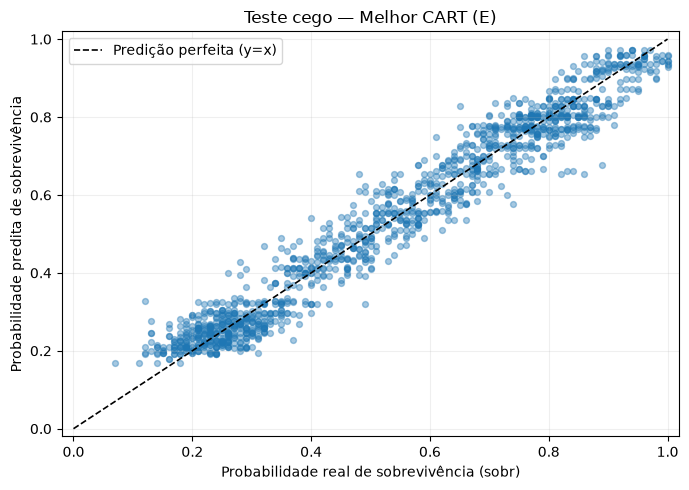

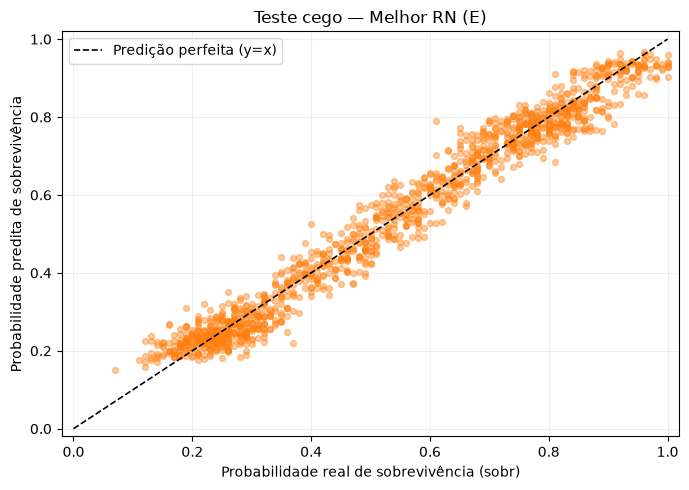

In [19]:
intervalos_predicoes = pd.DataFrame({
    nome_cart_final: {
        "Mínimo": pred_cart.min(), "Máximo": pred_cart.max(),
        "Fora de [0, 1]": int(((pred_cart < 0) | (pred_cart > 1)).sum()),
    },
    nome_rn_final: {
        "Mínimo": pred_rn.min(), "Máximo": pred_rn.max(),
        "Fora de [0, 1]": int(((pred_rn < 0) | (pred_rn > 1)).sum()),
    },
}).T
display(intervalos_predicoes)

limite_inferior = min(0.0, pred_cart.min(), pred_rn.min())
limite_superior = max(1.0, pred_cart.max(), pred_rn.max())
referencia = [limite_inferior, limite_superior]
PASTA_GRAFICOS.mkdir(parents=True, exist_ok=True)
for nome, predicoes, cor in [
    (nome_cart_final, pred_cart, "tab:blue"),
    (nome_rn_final, pred_rn, "tab:orange"),
]:
    fig, ax = plt.subplots(figsize=(7, 5))
    ax.scatter(y_test, predicoes, s=18, alpha=0.4, color=cor)
    ax.plot(referencia, referencia, "k--", linewidth=1.2, label="Predição perfeita (y=x)")
    ax.set_xlim(limite_inferior - 0.02, limite_superior + 0.02)
    ax.set_ylim(limite_inferior - 0.02, limite_superior + 0.02)
    ax.set_xlabel("Probabilidade real de sobrevivência (sobr)")
    ax.set_ylabel("Probabilidade predita de sobrevivência")
    ax.set_title(f"Teste cego — {nome}")
    ax.grid(alpha=0.2)
    ax.legend()
    fig.tight_layout()
    sufixo = "cart" if nome == nome_cart_final else "rn"
    fig.savefig(PASTA_GRAFICOS / f"real_x_predito_{sufixo}.png")
    plt.show()

## 14. Salvamento e verificação dos modelos finais

Salvamos a árvore, a MLP e seu scaler em arquivos separados, com os nomes
exigidos e em uma pasta exclusiva. Os arquivos ficam em `modelos/regressor/`. Para usar a MLP depois: selecione as colunas
na ordem de `FEATURES`, transforme com `scaler.joblib` e então chame `predict`.
Recarregamos os arquivos e verificamos as previsões em cinco linhas de **treino**,
sem repetir a avaliação do teste cego.

In [20]:
PASTA_MODELOS.mkdir(parents=True, exist_ok=True)
joblib.dump(melhor_cart, PASTA_MODELOS / "melhor_cart.joblib")
joblib.dump(melhor_rn, PASTA_MODELOS / "melhor_rn.joblib")
joblib.dump(scaler_final, PASTA_MODELOS / "scaler.joblib")
for nome_arquivo in ["melhor_cart.joblib", "melhor_rn.joblib", "scaler.joblib"]:
    caminho = PASTA_MODELOS / nome_arquivo
    assert caminho.is_file() and caminho.stat().st_size > 0
    print("Salvo:", caminho.relative_to(BASE))

cart_recarregado = joblib.load(PASTA_MODELOS / "melhor_cart.joblib")
rn_recarregada = joblib.load(PASTA_MODELOS / "melhor_rn.joblib")
scaler_recarregado = joblib.load(PASTA_MODELOS / "scaler.joblib")
amostra_integridade = X.head()
np.testing.assert_allclose(
    cart_recarregado.predict(amostra_integridade), melhor_cart.predict(amostra_integridade)
)
with threadpool_limits(limits=1):
    np.testing.assert_allclose(
        rn_recarregada.predict(scaler_recarregado.transform(amostra_integridade)),
        melhor_rn.predict(scaler_final.transform(amostra_integridade)),
    )
assert scaler_recarregado.feature_names_in_.tolist() == FEATURES
assert np.all(np.asarray(scaler_recarregado.n_samples_seen_) == N_VITIMAS)
print("Integridade dos três arquivos confirmada.")

Salvo: tarefa2_modelos/melhor_cart.joblib
Salvo: tarefa2_modelos/melhor_rn.joblib
Salvo: tarefa2_modelos/scaler.joblib
Integridade dos três arquivos confirmada.


## 15. RESULTADOS PARA O RELATÓRIO

As sete tabelas abaixo reúnem somente resultados **já calculados**, sem retreino
ou nova avaliação. As tabelas 3, 5 e 6 usam **média (DPA amostral dos cinco folds)**.
Na tabela 1, distinguimos parâmetros da geração e estatísticas observadas:
o DPA amostral real da idade não é necessariamente igual a `desvio_idade=15`.
Os dois gráficos finais estão na seção 13 e permanecem nas saídas do notebook.

In [21]:
tabela_dataset = pd.Series({
    **{f"Vítimas tri={nome}": int(contagem_tri.loc[tri])
       for tri, nome in NOMES_TRI.items()},
    "Total de vítimas": len(df),
    "Idade das vítimas (média observada)": media_idade_observada,
    "Desvio padrão amostral da idade (observado, ddof=1)": dpa_idade_observado,
    "media_idade (parâmetro de geração)": config_geracao["media_idade"],
    "desvio_idade (parâmetro de geração)": config_geracao["desvio_idade"],
    "Ruído (nivel_ruido configurado)": config_geracao["nivel_ruido"],
    "Desvio do ruído fisiológico de sobr (fixo no gerador)": 0.04,
    "Semente de geração": config_geracao["seed"],
    "Número de folds": N_FOLDS,
    "Distribuição inicial (distrib_tri)": str(config_geracao["distrib_tri"]),
}, name="Valor").to_frame()

print("TABELA 1 — DATASET")
display(tabela_dataset)
print("TABELA 2 — HIPERPARAMETRIZAÇÕES CART")
display(tabela_hiperparametros_cart)
print("TABELA 3 — RESULTADOS CART: média (DPA)")
display(tabela_cart)
print("TABELA 4 — HIPERPARAMETRIZAÇÕES REDE NEURAL")
display(tabela_hiperparametros_rn)
print("TABELA 5 — RESULTADOS RN: média (DPA)")
display(tabela_rn)
print("TABELA 6 — MELHOR CART × MELHOR RN: média (DPA)")
display(tabela_melhores)
print("TABELA 7 — TESTE CEGO")
display(tabela_teste_apresentacao)

TABELA 1 — DATASET


,Valor
Vítimas tri=verde,2478
Vítimas tri=amarelo,2516
Vítimas tri=vermelho,2534
Vítimas tri=preto,2472
Total de vítimas,10000
Idade das vítimas (média observada),34.541600
"Desvio padrão amostral da idade (observado, ddof=1)",14.869720
media_idade (parâmetro de geração),35
desvio_idade (parâmetro de geração),15
Ruído (nivel_ruido configurado),0.020000


TABELA 2 — HIPERPARAMETRIZAÇÕES CART


,U,E,O
max_depth,2,10,None
min_samples_leaf,100,20,1
criterion,squared_error,squared_error,squared_error
random_state,42,42,42


TABELA 3 — RESULTADOS CART: média (DPA)


...

,RN U,RN E,RN O
TREINO MSE (dpa),0.002698 (0.000023),0.001747 (0.000009),0.000629 (0.000026)
VALIDAÇÃO MSE (dpa),0.002709 (0.000062),0.001773 (0.000038),0.002959 (0.000077)
MÉDIA DAS DIFS. (dpa),0.000051 (0.000053),0.000033 (0.000040),0.002330 (0.000090)


TABELA 6 — MELHOR CART × MELHOR RN: média (DPA)


,Melhor CART (E),Melhor RN (E)
TREINO MSE (dpa),0.001790 (0.000007),0.001747 (0.000009)
VALIDAÇÃO MSE (dpa),0.002332 (0.000051),0.001773 (0.000038)
MÉDIA DAS DIFS. (dpa),0.000543 (0.000054),0.000033 (0.000040)


TABELA 7 — TESTE CEGO


,Melhor CART (E),Melhor RN (E)
MSE,0.002798,0.001858
Ganho % MSE,—,33.619704
RMSE,0.052900,0.043100
Ganho % RMSE,—,18.525896


### Resumo final e conferência dos comportamentos

Usamos os erros da validação para verificar U/E/O. As verificações abaixo
confirmam o contraste didático desta execução; não definem limites universais
para subajuste ou sobreajuste. A preferência por uma família já foi fixada na
validação cruzada. O vencedor do teste cego é apenas informado no resumo.

In [22]:
for familia, resumo in [("CART", resumo_cart), ("RN", resumo_rn)]:
    assert resumo.loc["U", "train_mean"] > resumo.loc["E", "train_mean"]
    assert resumo.loc["U", "val_mean"] > resumo.loc["E", "val_mean"]
    assert resumo.loc["O", "train_mean"] < resumo.loc["E", "train_mean"]
    assert resumo.loc["O", "val_mean"] > resumo.loc["E", "val_mean"]
    assert resumo.loc["O", "diff_mean"] > resumo.loc["E", "diff_mean"]
    print(f"{familia}: U com erros maiores; O com treino menor e gap maior; "
          "E com melhor validação entre as três configurações.")

print("\nMelhor CART:", melhor_cart_config, parametros_melhor_cart)
print("Melhor RN:", melhor_rn_config, parametros_melhor_rn)
print("Modelo preferido na validação:", modelo_preferido_cv)
print(f"\nTeste cego: {len(test_df)} vítimas")
print(f"CART MSE = {mse_cart:.6f}; CART RMSE = {rmse_cart:.6f}")
print(f"RN MSE = {mse_rn:.6f}; RN RMSE = {rmse_rn:.6f}")
print("Menor erro no teste cego:", vencedor_teste)
print(f"Ganho MSE = {ganho_mse:.6f}%; ganho RMSE = {ganho_rmse:.6f}%")
print("Modelos:", PASTA_MODELOS.relative_to(BASE))
print("Previsões fora de [0, 1]:")
display(intervalos_predicoes[["Fora de [0, 1]"]])
print("Convenção adotada: MSE sem raiz; RMSE = sqrt(MSE).")

CART: U com erros maiores; O com treino menor e gap maior; E com melhor validação entre as três configurações.
RN: U com erros maiores; O com treino menor e gap maior; E com melhor validação entre as três configurações.

Melhor CART: E {'max_depth': 10, 'min_samples_leaf': 20}
Melhor RN: E {'hidden_layer_sizes': (32, 16), 'activation': 'relu', 'solver': 'adam', 'alpha': 0.1, 'learning_rate_init': 0.001, 'max_iter': 1500, 'tol': 1e-06, 'n_iter_no_change': 40}
Modelo preferido na validação: Melhor RN (E)

Teste cego: 1300 vítimas
CART MSE = 0.002798; CART RMSE = 0.052900
RN MSE = 0.001858; RN RMSE = 0.043100
Menor erro no teste cego: Melhor RN (E)
Ganho MSE = 33.619704%; ganho RMSE = 18.525896%
Modelos: tarefa2_modelos
Previsões fora de [0, 1]:


,"Fora de [0, 1]"
Melhor CART (E),0.000000
Melhor RN (E),0.000000


Convenção adotada: MSE sem raiz; RMSE = sqrt(MSE).
